# Finding corrections

> **In short.**
> * **The setting.** A protocol with measurements does a different map in each run. Usually the difference is a Pauli on its outputs that the outcomes determine (a *Pauli frame*): teleportation leaves $X^{m_2} Z^{m_1}$, lattice surgery leaves its *byproduct operators*. The protocol is completed by *corrections*: that Pauli, applied when the outcomes say so. Until now every example in this folder was given its corrections; here the tool finds them.
> * **How** (`find_corrections`). In the Z-X normal form of the program each output has an X-spider: the outcome part of its phase, $(c_i + c_j + \dots)\pi$, is an $X$ to apply when that parity is 1. With those applied, the X-Z normal form has a Z-spider on each output; rewriting Z-X into X-Z copies the outcome phases of the Z-spiders across to the outputs, and the outcome part of each is a $Z$ to apply. With both, the tool checks that every run is the run with every outcome 0; it tries no correction and the $X$ ones alone first, since an outcome phase on the outputs can be a check of the code, which needs no correction. The pictures of the rewrite are in [FindingCorrectionsStepByStep.ipynb](FindingCorrectionsStepByStep.ipynb).
> * **Three protocols, their corrections taken out.** Teleportation: $X$ when $m_2 = 1$, $Z$ when $m_1 = 1$. The CX by gate teleportation of [GateTeleportation.ipynb](GateTeleportation.ipynb), on the toric code: $X$ of t and $Z$ of c, controlled by the right outcomes, at the end instead of in the middle; with them, CX in every run. A CNOT by lattice surgery between three distance-2 surface-code patches (a $ZZ$ merge, an $XX$ merge and split, a measurement): the textbook byproducts, $X$ of the target and $Z$ of the control, plus one $X$ that repairs a check the split re-measured; with them, CNOT in every run.
> * **What it does not find.** A difference that is not a Pauli: in a $T$ injection the outcome turns $T$ into $T^\dagger$, whose correction is an $S$; the tool says so.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders. A phase `c[0]` means $\pi$ times that outcome.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, T, Measurement
from zxqec.qprogram import QProgram, find_corrections
from zxqec.gpf import reduce_gpf, x_z_normal_form
from zxqec.spacetime import draw_program

## 1. Teleportation

Qubit 0 holds the state to teleport; qubits 1 and 2 are prepared in a Bell pair; qubits 0 and 1 are measured in the Bell basis (results `c[0]` and `c[1]`). Without corrections, the tool finds the identity followed by a Pauli that the outcomes decide.

In [2]:
teleport = QProgram(3, bits=2, initial_states={1: '0', 2: '0'})
c = Circuit(3, bit_amount=2)
for gate in [HAD(1), CNOT(1, 2), CNOT(0, 1), HAD(0), Measurement(0, 0), Measurement(1, 1)]:
    c.add_gate(gate)
teleport.add_circuit(c, name='teleport')
print(teleport.logical_action().verdict())

deterministic up to a Pauli frame: every run implements I followed by a Pauli correction (X, Y, Z, none) that the outcomes determine


The two normal forms of this program. Z-X: the input's Z-spider carries `c[0]` and the output's X-spider `c[1]`, an $X$ on the output when `c[1]` is 1. X-Z: the X-spider with `c[1]` is now on the input side and the Z-spider with `c[0]` on the output: a $Z$ on the output when `c[0]` is 1.

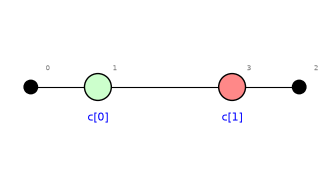

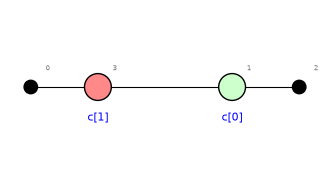

In [3]:
display(zx.draw_matplotlib(reduce_gpf(teleport.quantum_graph()).to_graph(), labels=True, figsize=(4, 2)))
zx.draw_matplotlib(x_z_normal_form(teleport.quantum_graph())[0], labels=True, figsize=(4, 2))

In [4]:
fix = find_corrections(teleport)
print(fix)
c = Circuit(3, bit_amount=2)
for gate in fix.gates():
    c.add_gate(gate)
teleport.add_circuit(c, name='corrections')
print("\nwith the corrections:", teleport.logical_action().verdict())

X on qubit 2 when c[1] = 1
Z on qubit 2 when c[0] = 1
with them, every run is the run with every outcome 0

with the corrections: deterministic: every run implements I


## 2. The CX by gate teleportation, without its corrections

The program of [GateTeleportation.ipynb](GateTeleportation.ipynb) (the toric code on a 2×2 torus: data block on qubits 0–7, ancilla on 8–15, helper 16), with its three corrections left out: $X$ of c on the ancilla and on the data block after the first teleportation, and $Z$ of c on the data block at the end. Without them the tool finds a CX followed by a Pauli that the outcomes decide.

In [5]:
X_C, Z_C = [0, 4], [0, 2]
TORIC = Circuit(8)
for gate in [CNOT(2, 6), CNOT(5, 7), HAD(0), CNOT(0, 2), CNOT(0, 4), CNOT(0, 6), HAD(1), CNOT(1, 4), CNOT(1, 5),
             CNOT(1, 6), HAD(3), CNOT(3, 4), CNOT(3, 6), CNOT(3, 7)]:
    TORIC.add_gate(gate)
REFLECT = [(0, 1), (2, 5), (3, 4), (6, 7)]
gate_teleport = QProgram(17, bits=10, initial_states={**{q: '0' for q in range(17) if q not in (2, 5)}, 10: '+'})
for name, gates in (('toric code', None), ('ancilla |+0>', None),
                    ('teleport c in', [CNOT(8 + j, j) for j in range(8)] + [CNOT(q, 16) for q in Z_C] + [Measurement(16, 0)]),
                    ('transversal CX', [CNOT(8 + j, j) for j in range(8)]),
                    ('teleport c back', [CNOT(8 + j, j) for j in range(8)] + [g for j in range(8) for g in (HAD(8 + j), Measurement(8 + j, 2 + j))])):
    c = Circuit(17, bit_amount=10)
    if gates is None:
        c.add_circuit(TORIC, mask=list(range(8)) if name == 'toric code' else list(range(8, 16)), bit_mask=[])
    else:
        for gate in gates:
            c.add_gate(gate)
    if name == 'transversal CX':
        gate_teleport.add_permutation([(8 + a, 8 + b) for a, b in REFLECT], cycles=True, name='swap c and t')
        gate_teleport.add_circuit(c, name=name, physical=True)
        gate_teleport.add_permutation([(8 + a, 8 + b) for a, b in REFLECT], cycles=True, name='swap back')
    else:
        gate_teleport.add_circuit(c, name=name)
print(gate_teleport.logical_action().verdict())

deterministic up to a Pauli frame: every run implements CNOT(0->1) followed by a Pauli correction (IX, ZI, ZX, none) that the outcomes determine


The corrections the tool finds: $X$ on qubits 1 and 3, the $X$ of t, when `c[0]` is 1; and $Z$ on qubits 4 and 6 when `c[2] + c[6]` is 1, the $Z$ of c times a Z check (Z on 0, 2, 4, 6). GateTeleportation.ipynb corrects in the middle of the protocol; Paulis commute with the gates after them up to Paulis, so the tool puts them all at the end.

In [6]:
fix = find_corrections(gate_teleport)
print(fix)
c = Circuit(17, bit_amount=10)
for gate in fix.gates():
    c.add_gate(gate)
gate_teleport.add_circuit(c, name='corrections')
print("\nwith the corrections:", gate_teleport.logical_action().verdict())

X on qubit 1 when c[0] = 1
X on qubit 3 when c[0] = 1
Z on qubit 4 when c[2] + c[6] = 1
Z on qubit 6 when c[2] + c[6] = 1
with them, every run is the run with every outcome 0

with the corrections: deterministic: every run implements CNOT(0->1)


## 3. A CNOT by lattice surgery

Three surface-code patches of distance 2 (`surface_code_checks(2)`: four qubits in a square, an X check on all four, a Z check on each column; logical $X$ on a column, logical $Z$ on a row). The ancilla patch A is on qubits 0–3, the control C below it on 4–7, the target T to its right on 8–11, laid out on one grid:

|   | col 0 | col 1 | col 2 | col 3 |
|---|---|---|---|---|
| row 0 | A 0 | A 1 | T 8 | T 9 |
| row 1 | A 2 | A 3 | T 10 | T 11 |
| row 2 | C 4 | C 5 | | |
| row 3 | C 6 | C 7 | | |

*Lattice surgery* measures a product of logical operators of two patches by measuring checks across their boundary as if they were one patch (a *merge*), then the old boundary checks again (a *split*). The CNOT from C to T: prepare A in $|+\rangle$; merge C and A, measuring $Z_C Z_A$: here one new check, $Z$ on the face across the boundary (qubits 2, 3, 4, 5; result `c[0]`); merge A and T, measuring $X_A X_T$: two new X checks across the boundary (qubits 1, 8 and 3, 10; `c[1]`, `c[2]`); split them, measuring A's and T's Z checks on the boundary columns again (`c[3]`, `c[4]`); measure A in the Z basis (`c[5]` to `c[8]`). Each check is measured with a helper qubit (12–16).

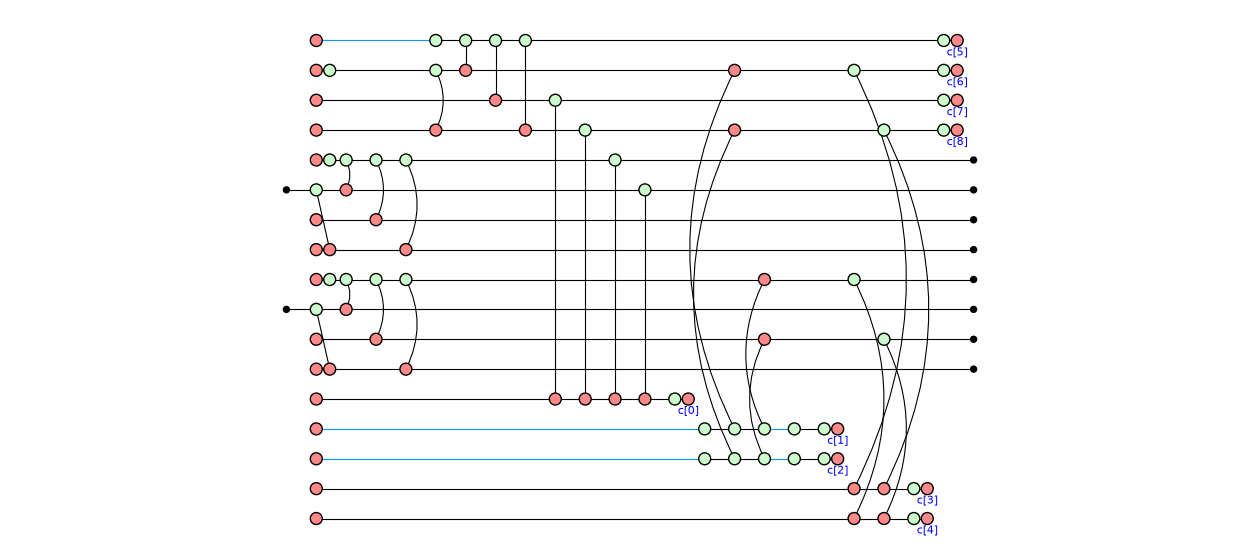

In [7]:
A, C_, T_ = [0, 1, 2, 3], [4, 5, 6, 7], [8, 9, 10, 11]
# each patch encoded from its qubit 1 (the input of C and T, |+> for A): the X check on all four, logical X on qubits 1, 3
ENCODE = {p: [CNOT(p[1], p[3]), HAD(p[0]), CNOT(p[0], p[1]), CNOT(p[0], p[2]), CNOT(p[0], p[3])] for p in (tuple(A), tuple(C_), tuple(T_))}
surgery = QProgram(17, bits=9, initial_states={**{q: '0' for q in range(17) if q not in (5, 9)}, 1: '+'})
for name, gates in (('encode C and T', ENCODE[tuple(C_)] + ENCODE[tuple(T_)]),
                    ('ancilla |+>', ENCODE[tuple(A)]),
                    ('merge C, A: Z Z', [CNOT(q, 12) for q in (2, 3, 4, 5)] + [Measurement(12, 0)]),
                    ('merge A, T: X X', [g for h, qs, bit in ((13, (1, 8), 1), (14, (3, 10), 2))
                                         for g in [HAD(h)] + [CNOT(h, q) for q in qs] + [HAD(h), Measurement(h, bit)]]),
                    ('split A, T', [g for h, qs, bit in ((15, (1, 3), 3), (16, (8, 10), 4))
                                    for g in [CNOT(q, h) for q in qs] + [Measurement(h, bit)]]),
                    ('measure A', [Measurement(q, 5 + k) for k, q in enumerate(A)])):
    c = Circuit(17, bit_amount=9)
    for gate in gates:
        c.add_gate(gate)
    surgery.add_circuit(c, name=name)
draw_program(surgery, show_time=False, labels=False, figsize=(16, 7))

Question 1 during the merge: after the $XX$ merge, A and T are one code, the patch of qubits 0–3 and 8–11 (eight qubits, one logical qubit: of A's and T's two, the measurement of $X_A X_T$ took one); C is a code of its own. Question 2 for the whole program: a CNOT from C to T, up to a Pauli the outcomes decide.

In [8]:
for block in surgery.code_at(3).blocks():
    print(block.describe().splitlines()[0])
print("\n", surgery.logical_action().verdict())

[[8, 1, 2]] CSS code on qubits 0, 1, 2, 3, 8, 9, 10, 11
[[4, 1, 2]] CSS code on qubits 4, 5, 6, 7

 deterministic up to a Pauli frame: every run implements CNOT(0->1) followed by a Pauli correction (IX, ZI, ZX, none) that the outcomes determine


The corrections the tool finds: on T, $X$ on qubits 9 and 11 (the logical $X$ of T) when `c[0] + c[3] + c[5] + c[6]` is 1 ($Z_C Z_A$, the split, and A's logical $Z$ on its row 0), and $X$ on qubit 8 when `c[3]` is 1, which puts back the sign of T's boundary check that the split measured; on C, $Z$ on qubits 4 and 5 (the logical $Z$ of C) when `c[1] + c[2]` is 1 ($X_A X_T$). These are the byproducts of the lattice-surgery CNOT, $X_T^{m_{ZZ} + m_A}$ and $Z_C^{m_{XX}}$, written on these patches. With them, a CNOT in every run.

In [9]:
fix = find_corrections(surgery)
print(fix)
c = Circuit(17, bit_amount=9)
for gate in fix.gates():
    c.add_gate(gate)
surgery.add_circuit(c, name='corrections')
print("\nwith the corrections:", surgery.logical_action().verdict())

X on qubit 8 when c[3] = 1
X on qubit 9 when c[0] + c[3] + c[5] + c[6] = 1
X on qubit 11 when c[0] + c[3] + c[5] + c[6] = 1
Z on qubit 4 when c[1] + c[2] = 1
Z on qubit 5 when c[1] + c[2] = 1
with them, every run is the run with every outcome 0

with the corrections: deterministic: every run implements CNOT(0->1)


## 4. What Pauli corrections cannot do

A $T$ injection on two qubits: $T|+\rangle$ on qubit 1, a CNOT, qubit 1 measured. When the outcome is 1 the input gets $T^\dagger$ instead of $T$: the difference is an $S$, not a Pauli, and the tool reports that no Pauli correction makes every run the same.

In [10]:
injection = QProgram(2, bits=1, initial_states={1: '0'})
c = Circuit(2, bit_amount=1)
for gate in [HAD(1), T(1), CNOT(0, 1), Measurement(1, 0)]:
    c.add_gate(gate)
injection.add_circuit(c, name='inject T')
print(injection.logical_action().verdict())
print(find_corrections(injection))

not deterministic: the operation depends on the outcomes (T when c[0] = 0; T^dag when c[0] = 1)
no Pauli correction found
with them, the program still depends on its outcomes (a difference that is not a Pauli)


## Summary

* `find_corrections` reads Pauli corrections off the Z-X normal form (the $X$ ones) and the X-Z normal form (the $Z$ ones), and checks that with them every run is the run with every outcome 0 (fewer corrections first: an outcome phase on the outputs can be a check of the code).
* It finds the corrections of teleportation, of the gate teleportation of [GateTeleportation.ipynb](GateTeleportation.ipynb) (at the end instead of in the middle), and of a CNOT by lattice surgery on distance-2 surface-code patches, including the repair of a check re-measured by the split.
* A difference that is not a Pauli, as in a $T$ injection, is reported, not corrected.

What is not covered: the corrections are put at the end of the program; a protocol that needs them earlier (before a non-Clifford gate, as in the injection) needs them moved, which is not done here. Only Pauli corrections are found. The lattice surgery is one round of each merge, with no noise and patches of distance 2; real patches repeat their checks.